Predict sales based on advertising spend on tv, radio and newspapers

In [1]:
# Importing necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime

# Retrieve the data
sales = pd.read_csv("advertising.csv")
sales.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [2]:
tv = sales["TV"]
radio = sales["Radio"]
newspaper = sales["Newspaper"]
total_sales = sales["Sales"]

predicted_sales = pd.DataFrame({
    "TV": tv,
    "Radio": radio,
    "Newspaper": newspaper,
    "Total Sales": total_sales})
predicted_sales.head()

,TV,Radio,Newspaper,Total Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


<Axes: xlabel='TV', ylabel='Total Sales'>

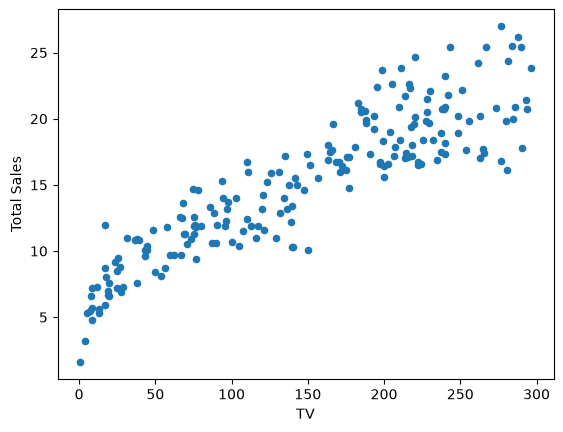

In [3]:
predicted_sales.plot.scatter("TV","Total Sales")

<Axes: xlabel='Radio', ylabel='Total Sales'>

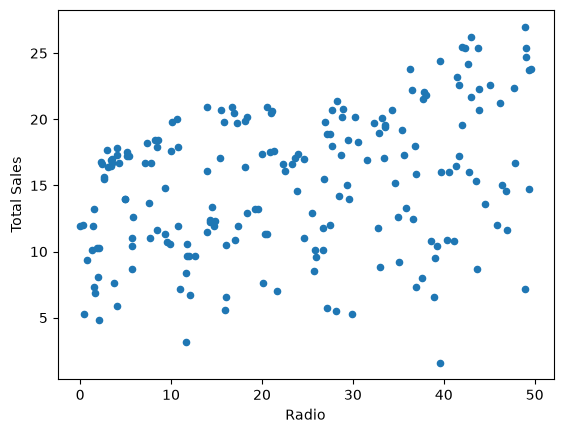

In [4]:
predicted_sales.plot.scatter("Radio","Total Sales")

<Axes: xlabel='Newspaper', ylabel='Total Sales'>

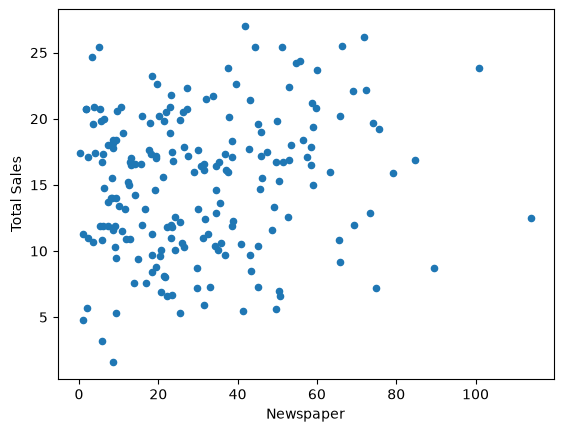

In [5]:
predicted_sales.plot.scatter("Newspaper","Total Sales")

In [6]:
# Importing Linear Regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

In [7]:
# 1 - Defining X and Y
X = predicted_sales[["TV", "Radio", "Newspaper"]]
y = predicted_sales["Total Sales"]

# 2 - Separating input values (features) and the expected output (label) into separate numpy arrays
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

# 3 - Define the LinearRegression object and fit it to the data using the fit() method
lin_reg = LinearRegression() # Create linear regression
lin_reg.fit(X_train,y_train) # Fit the linear regression

# 4 - After fitting the model, view the value of coffecients
print ("Intercept value: ", lin_reg.intercept_) # View the intercept

# 5 - View the feature coefficient
print ("Slope value: ", lin_reg.coef_)

# 6 - Predict the target value
pred = lin_reg.predict(X_test)
mse = np.sqrt(mean_squared_error(y_test,pred))
print(f"Root Mean Square Error: {mse:3.3} ({mse/np.mean(pred) * 100:3.3}%)")

# 7 - Coefficient of determination
score = lin_reg.score(X_train,y_train)
print("Model determination (R² score): ", score) 

Intercept value:  4.773205203269834
Slope value:  [ 0.05368006  0.11152624 -0.00351166]
Root Mean Square Error: 2.13 (14.8%)
Model determination (R² score):  0.9132130769530317


In [8]:
lin_reg.coef_, lin_reg.intercept_
lin_reg.predict(pd.DataFrame({"TV": [80], "Radio": [40], "Newspaper": [40]}))

array([13.3881926])

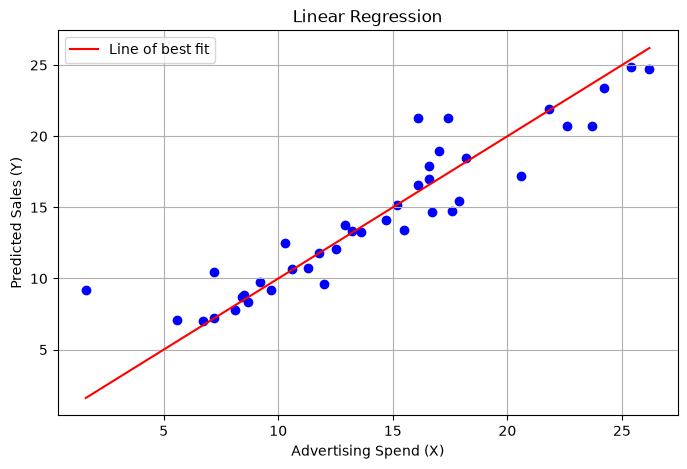

In [9]:
# 8 - Creating a graph to visualise the data
plt.figure(figsize = (8,5))
plt.scatter(y_test, pred, color = "Blue")
plt.plot(
    [min(y_test), max(y_test)],
    [min(y_test), max(y_test)],
    label = "Line of best fit",
    color = "Red",
)
plt.title("Linear Regression")
plt.xlabel("Advertising Spend (X)")
plt.ylabel("Predicted Sales (Y)")
plt.grid(True)
plt.legend()
plt.show()